[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.3/Problem_3.21.ipynb)

# Chapter 3, Problem 21 — outward normals in the $t$–$x$ plane

**Problem.**
- **(a)** Let a region of the $t$–$x$ plane be bounded by the lines $t = 0$, $t = 1$, $x = 0$, $x = 1$. Within the $t$–$x$ plane, find the unit outward normal one-forms and their associated vectors for each of the boundary lines.
- **(b)** Let another region be bounded by the straight lines joining the events whose coordinates are $(1, 0)$, $(1, 1)$, and $(2, 1)$. Find an outward normal for the null boundary and find its associated vector.

**Tools.**
- A normal one-form to the line $f = $ const is a multiple of $\tilde df$ (Problems 12, 13).
- **Outward** means positive on vectors pointing out of the region (Problem 12b: a normal one-form is positive on all vectors to one side).
- **Unit** means $|\tilde n|^2 = \eta^{\alpha\beta}n_\alpha n_\beta = \pm1$.
- Associated vector: $n^\alpha = \eta^{\alpha\beta}n_\beta$: flip the sign of the $t$ component.

Coordinates are written $(t, x)$ throughout, as in the problem.

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

## (a) The unit square $0 \le t \le 1$, $0 \le x \le 1$

**Bottom, $t = 0$.** Normal one-forms: multiples of $\tilde dt$. The outward direction is $-\vec e_t$ (toward smaller $t$), and $\tilde dt(-\vec e_t) = -1 < 0$, so take $\tilde n = -\tilde dt \to (-1, 0)$. Norm $\eta^{tt}(-1)^2 = -1$: unit (timelike). Associated vector: $n^t = -n_t = +1$, $n^x = 0$, so $\vec n = +\vec e_t$.

**Top, $t = 1$.** Outward is $+\vec e_t$: $\tilde n = \tilde dt \to (1, 0)$, vector $\vec n = -\vec e_t$.

**Left, $x = 0$.** Outward is $-\vec e_x$: $\tilde n = -\tilde dx \to (0, -1)$, norm $+1$ (spacelike), vector $\vec n = -\vec e_x$.

**Right, $x = 1$.** $\tilde n = \tilde dx \to (0, 1)$, vector $\vec n = +\vec e_x$.

| boundary | outward unit normal one-form $(n_t, n_x)$ | associated vector $(n^t, n^x)$ | $\tilde n^2$ |
|---|---|---|---|
| $t = 0$ | $-\tilde dt \to (-1, 0)$ | $\vec e_t \to (1, 0)$ | $-1$ |
| $t = 1$ | $\tilde dt \to (1, 0)$ | $-\vec e_t \to (-1, 0)$ | $-1$ |
| $x = 0$ | $-\tilde dx \to (0, -1)$ | $-\vec e_x \to (0, -1)$ | $+1$ |
| $x = 1$ | $\tilde dx \to (0, 1)$ | $\vec e_x \to (0, 1)$ | $+1$ |

**The surprise.** On the spacelike boundaries $t = 0, 1$, the outward normal *one-form* gives positive values on outward vectors, but its associated *vector* points **inward**. Raising the index flips the time component. The outward normal vector concept is thus ambiguous for these boundaries; the one-form is the reliable object. (This matters for Gauss's law in spacetime, §4.8.)

## (b) The triangle $(1,0)$, $(1,1)$, $(2,1)$

The three sides, in $(t, x)$:
- $(1,0)$–$(1,1)$: the line $t = 1$ (spacelike segment; the region lies at $t \ge 1$).
- $(1,1)$–$(2,1)$: the line $x = 1$ (timelike segment; the region lies at $x \le 1$).
- $(1,0)$–$(2,1)$: the line $t - x = 1$, slope $dt/dx = 1$: a **null** line. The third vertex $(1, 1)$ has $t - x = 0 < 1$, so the region lies on the side $t - x \le 1$.

**Normal to the null side.** Let $f = t - x$; the side is $f = 1$, so normals are multiples of $\tilde df = \tilde dt - \tilde dx \to (1, -1)$. Outward means toward **increasing** $f$ (the interior has $f \le 1$). Check with a vector from the side outward, e.g. $\vec V \to (1, 0)$ (from $(1,0)$ straight up is outside, $f = 2$): $\tilde df(\vec V) = 1 > 0$ ✓. So
$$
\boxed{\tilde n = \tilde dt - \tilde dx \to (1, -1)} .
$$
It **cannot be normalized**: $\tilde n^2 = -(1)^2 + (-1)^2 = 0$, so no rescaling gives $\pm1$. Any positive multiple is an equally good outward normal.

**Associated vector:** $n^t = -n_t = -1$, $n^x = n_x = -1$:
$$
\boxed{\vec n \to (-1, -1)} = -(\vec e_t + \vec e_x).
$$
This vector is null and points along the line $t - x = $ const: it is **tangent** to the boundary it's "normal" to! Indeed $\vec n\cdot\vec n = 0$ means $\vec n$ is orthogonal to itself, and in 2-d the null line's tangent is $\propto\vec n$. (It also points into the past, toward $(1,0)$ from $(2,1)$.) This is the phenomenon flagged in Problem 12(d).

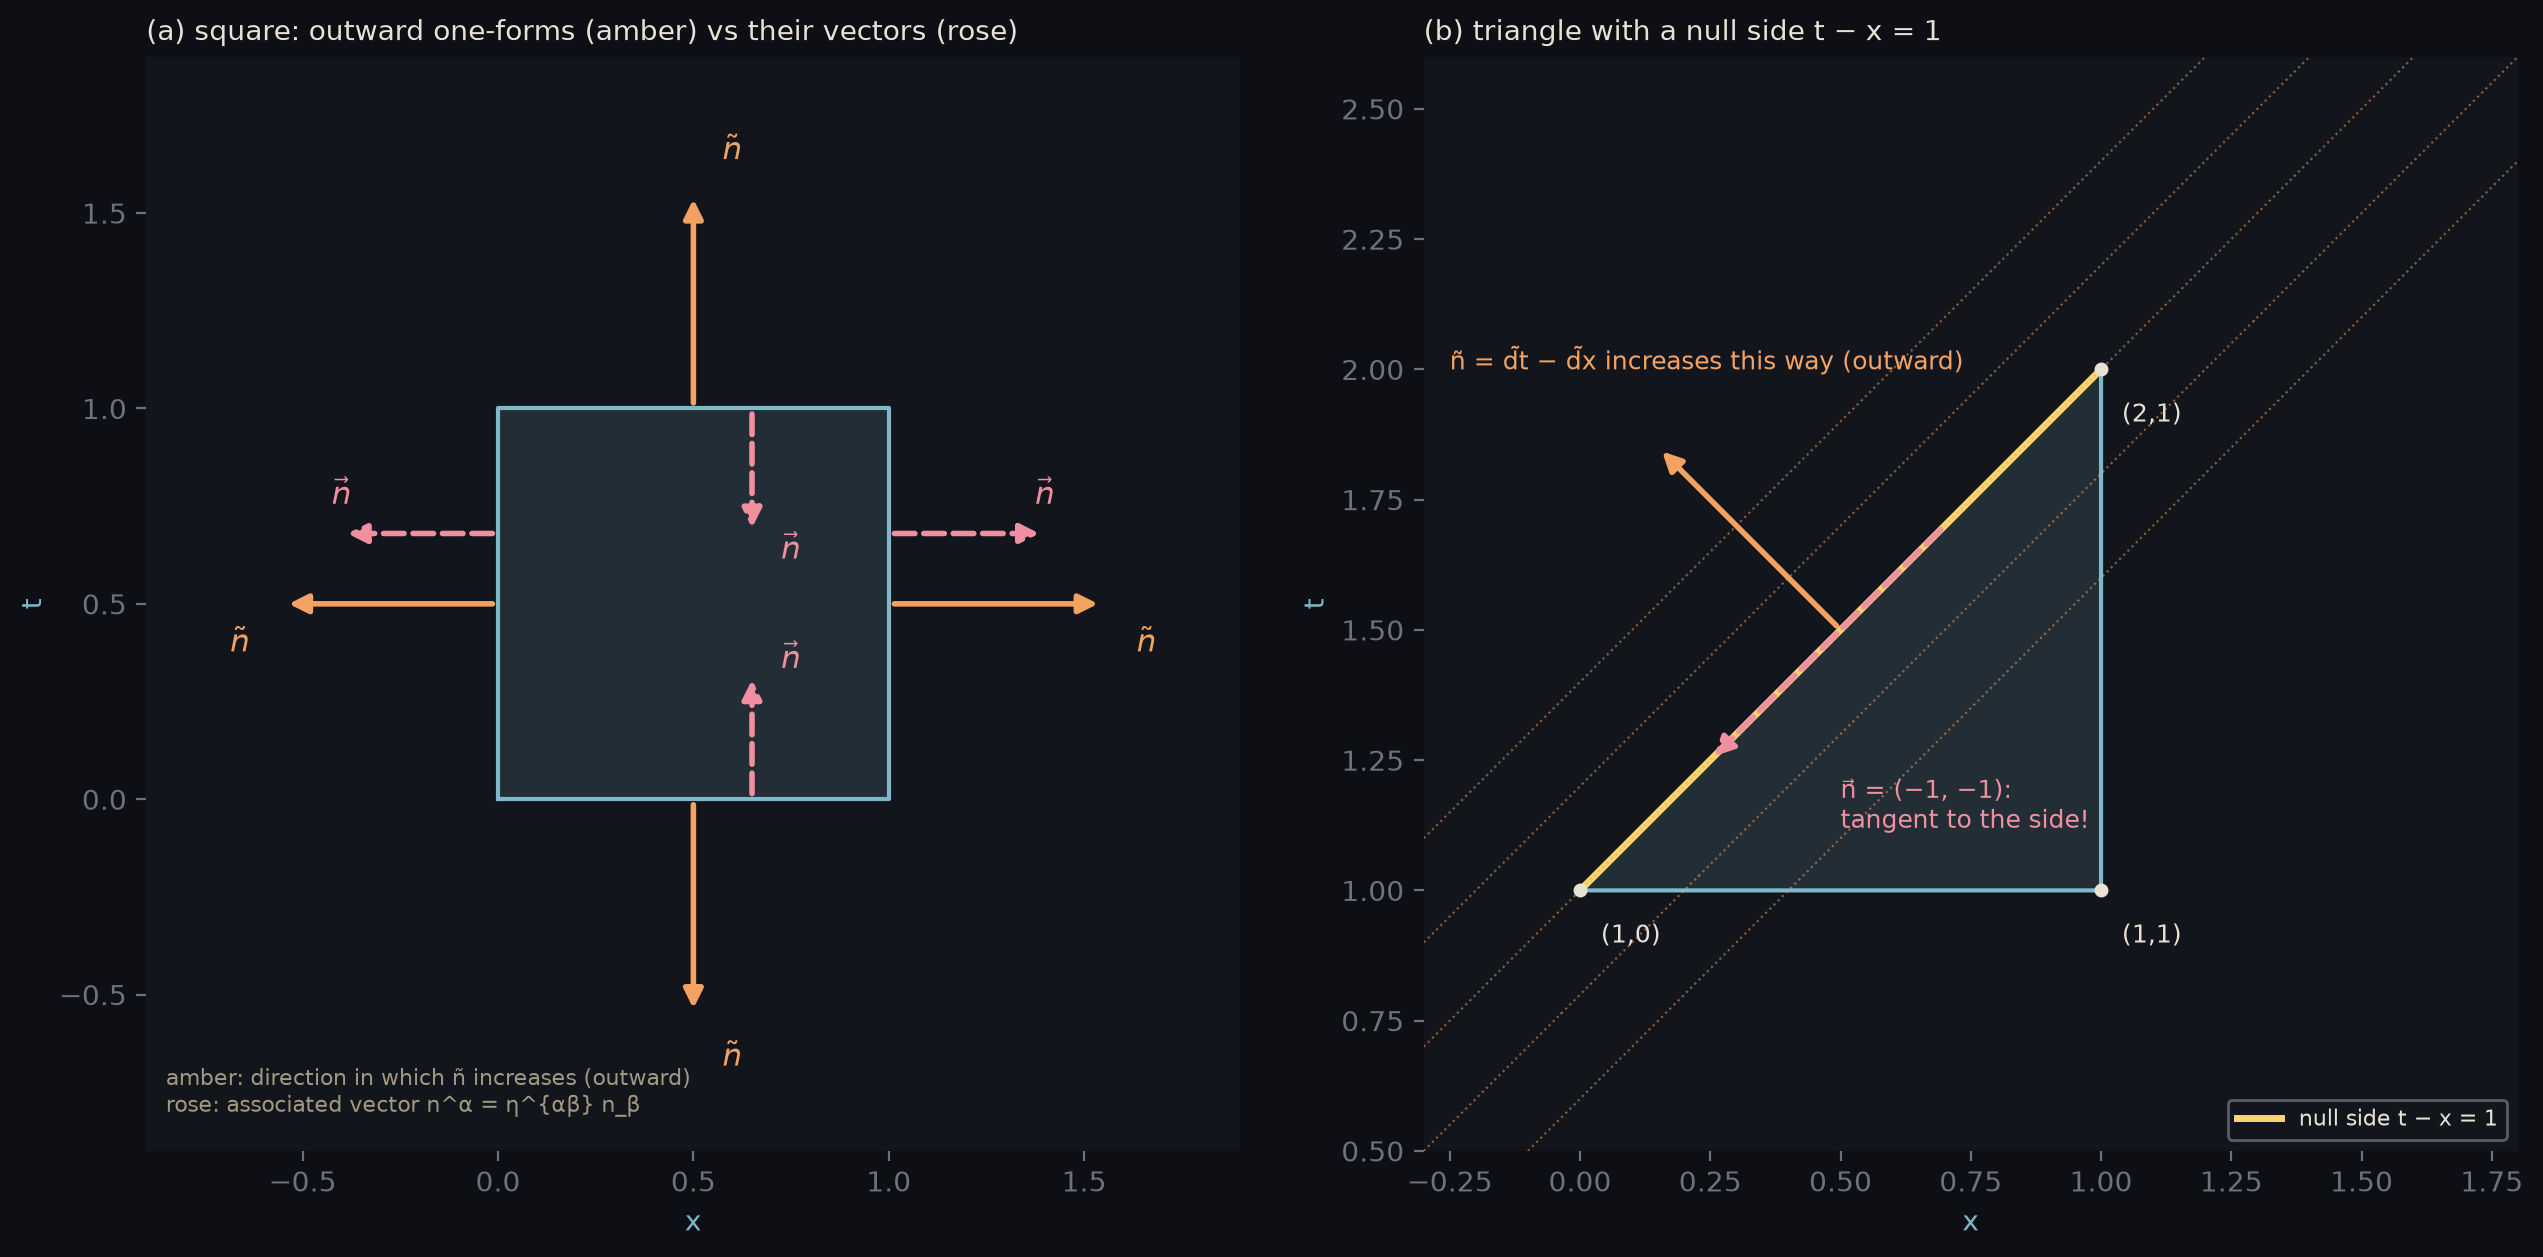

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from schutz_gr.diagrams import COLORS
%config InlineBackend.figure_format = 'retina'

def arr(ax, x0, t0, vx, vt, c, lab, off=(0.05, 0.05), ls="-"):
    ax.annotate("", xy=(x0 + vx, t0 + vt), xytext=(x0, t0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2, ls=ls, mutation_scale=14))
    ax.text(x0 + vx + off[0], t0 + vt + off[1], lab, color=c, fontsize=9)
def stack(ax, f, levels, xr, tr, c):           # draw a one-form's surfaces as level lines of f
    X, T = np.meshgrid(np.linspace(*xr, 200), np.linspace(*tr, 200))
    ax.contour(X, T, f(X, T), levels=levels, colors=c, linewidths=0.8, alpha=0.5, linestyles=":")
def style(ax, xl, tl, title):
    ax.set_facecolor(COLORS["panel"]); ax.set_xlim(*xl); ax.set_ylim(*tl); ax.set_aspect("equal")
    ax.tick_params(colors=COLORS["grey"]); ax.set_xlabel("x", color=COLORS["teal"]); ax.set_ylabel("t", color=COLORS["teal"])
    ax.set_title(title, color=COLORS["text"], loc="left", fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)

fig, axs = plt.subplots(1, 2, figsize=(13, 6.2)); fig.patch.set_facecolor(COLORS["bg"])
ax = axs[0]; style(ax, (-0.9, 1.9), (-0.9, 1.9), "(a) square: outward one-forms (amber) vs their vectors (rose)")
ax.fill([0, 1, 1, 0], [0, 0, 1, 1], color=COLORS["teal"], alpha=0.15); ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], color=COLORS["teal"])
# amber: one-form, drawn as an arrow in the direction it increases; rose dashed: the associated vector
def lab(x, y, txt, c): ax.text(x, y, txt, color=c, fontsize=11, ha="center", va="center")
for (x0, t0), (nt, nx) in {(0.5, 0): (-1, 0), (0.5, 1): (1, 0), (0, 0.5): (0, -1), (1, 0.5): (0, 1)}.items():
    arr(ax, x0, t0, 0.55*nx, 0.55*nt, COLORS["amber"], "", off=(0, 0))
    lab(x0 + 0.66*nx + (0.1 if nt else 0), t0 + 0.66*nt - (0.1 if nx else 0), r"$\tilde n$", COLORS["amber"])
    if nt:   # spacelike boundary: vector points inward
        xs = x0 + 0.15
        arr(ax, xs, t0, 0, -0.32*nt, COLORS["rose"], "", off=(0, 0), ls="--"); lab(xs + 0.1, t0 - 0.36*nt, r"$\vec n$", COLORS["rose"])
    else:
        ts = t0 + 0.18
        arr(ax, x0, ts, 0.4*nx, 0, COLORS["rose"], "", off=(0, 0), ls="--"); lab(x0 + 0.4*nx, ts + 0.1, r"$\vec n$", COLORS["rose"])
ax.text(-0.85, -0.8, "amber: direction in which ñ increases (outward)\nrose: associated vector n^α = η^{αβ} n_β", color=COLORS["muted"], fontsize=8)

ax = axs[1]; style(ax, (-0.3, 1.8), (0.5, 2.6), "(b) triangle with a null side t − x = 1")
P = np.array([[0, 1], [1, 1], [1, 2]])          # (x, t) for events (t,x) = (1,0), (1,1), (2,1)
ax.fill(P[:, 0], P[:, 1], color=COLORS["teal"], alpha=0.15); ax.plot(*np.vstack([P, P[:1]]).T, color=COLORS["teal"])
ax.plot([0, 1], [1, 2], color=COLORS["gold"], lw=2.5, label="null side t − x = 1")
stack(ax, lambda X, T: T - X, [0.6, 0.8, 1.0, 1.2, 1.4], (-0.3, 1.8), (0.5, 2.6), COLORS["amber"])
arr(ax, 0.5, 1.5, -0.35, 0.35, COLORS["amber"], "", off=(0, 0))
ax.text(-0.25, 2.0, "ñ = d̃t − d̃x increases this way (outward)", color=COLORS["amber"], fontsize=9)
arr(ax, 0.7, 1.7, -0.45, -0.45, COLORS["rose"], "", off=(0, 0), ls="--")
ax.text(0.5, 1.12, "n⃗ = (−1, −1):\ntangent to the side!", color=COLORS["rose"], fontsize=9)
for (x, t), lab in zip(P, ["(1,0)", "(1,1)", "(2,1)"]):
    ax.plot(x, t, "o", color=COLORS["text"], ms=4); ax.text(x + 0.04, t - 0.1, lab, color=COLORS["text"], fontsize=9)
ax.legend(loc="lower right", facecolor=COLORS["panel"], edgecolor=COLORS["grey"], labelcolor=COLORS["text"], fontsize=8)
plt.tight_layout(); plt.show()

In [3]:
import sympy as sp
eta = sp.diag(-1, 1)
for name, n in {"t=0": (-1, 0), "t=1": (1, 0), "x=0": (0, -1), "x=1": (0, 1), "null side": (1, -1)}.items():
    n = sp.Matrix(n); print(f"{name:10s} ñ = {list(n)}, n⃗ = {list(eta.inv()*n)}, ñ² = {(n.T*eta.inv()*n)[0]}")
# outwardness of the null normal: positive on a vector pointing from the side to the exterior point (t,x) = (2,0)
print("ñ(outward vector (1,0)) =", (sp.Matrix([1, -1]).T * sp.Matrix([1, 0]))[0])
print("n⃗ tangent to side t−x=1? d̃(t−x)(n⃗) =", (sp.Matrix([1, -1]).T * sp.Matrix([-1, -1]))[0])

t=0        ñ = [-1, 0], n⃗ = [1, 0], ñ² = -1
t=1        ñ = [1, 0], n⃗ = [-1, 0], ñ² = -1
x=0        ñ = [0, -1], n⃗ = [0, -1], ñ² = 1
x=1        ñ = [0, 1], n⃗ = [0, 1], ñ² = 1
null side  ñ = [1, -1], n⃗ = [-1, -1], ñ² = 0
ñ(outward vector (1,0)) = 1
n⃗ tangent to side t−x=1? d̃(t−x)(n⃗) = 0
